# Assignment 1: Data Profiling (EDA) Report
## Data Quality Assessment of Bank Marketing Data

### Team Members

| Name | Matric Number |
|---|---|
| Xia YanBo | A206724 |
| Qi YueKai | A206696 |
| Wang ShouLong | A207330 |
| Du JunZhi | A206711 |
### 1. Scenario

Financial organizations need reliable customer and campaign data for efficient data management and analysis. This project profiles a bank marketing dataset containing unknown information, extreme numerical values and possible privacy and sampling risks. We examine which data-quality problems exist, how they should be handled, and whether the processed data is suitable for analysing the recorded campaigns.

### 2. Data Source

The data was obtained from the UCI Machine Learning Repository's Bank Marketing dataset:

https://archive.ics.uci.edu/dataset/222/bank+marketing

We downloaded the dataset archive, extracted bank.zip, and selected bank-full.csv. The file contains 45,211 records and 17 columns, covering customer information and marketing campaign information from a Portuguese banking institution.

The CSV file uses a semicolon (;) as its delimiter. It was uploaded to Google Colab and loaded using pandas. This report uses one public dataset; it does not implement integration across multiple financial data sources.

Reference: Moro, S., Rita, P., & Cortez, P. (2014). Bank Marketing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306

### Instructions to Run

1. Open this notebook in Google Colab.
2. Download the dataset from the source above and extract bank-full.csv.
3. Run the first code cell and upload bank-full.csv when prompted.
4. Run all remaining code cells in order from top to bottom.
5. The notebook uses pandas and matplotlib, which are available in Google Colab.

The original data is stored in df. Processing is performed on a separate copy named df_clean to preserve the original records.

In [1]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

df = pd.read_csv(
    io.BytesIO(uploaded["bank-full.csv"]),
    sep=";"
)

display(df.head())
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Saving bank-full.csv to bank-full.csv


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Rows: 45211
Columns: 17


In [2]:
missing_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Null Count": df.isna().sum(),
    "Unknown Count": df.eq("unknown").sum()
})

missing_summary["Null Percentage (%)"] = (
    missing_summary["Null Count"] / len(df) * 100
).round(2)

missing_summary["Unknown Percentage (%)"] = (
    missing_summary["Unknown Count"] / len(df) * 100
).round(2)

display(missing_summary)

,Data Type,Null Count,Unknown Count,Null Percentage (%),Unknown Percentage (%)
age,int64,0,0,0.0,0.00
job,object,0,288,0.0,0.64
marital,object,0,0,0.0,0.00
education,object,0,1857,0.0,4.11
default,object,0,0,0.0,0.00
balance,int64,0,0,0.0,0.00
housing,object,0,0,0.0,0.00
loan,object,0,0,0.0,0.00
contact,object,0,13020,0.0,28.80
day,int64,0,0,0.0,0.00


In [3]:
history_check = pd.crosstab(
    df["pdays"].eq(-1),
    df["poutcome"]
)

history_check.index = history_check.index.map({
    True: "Not previously contacted",
    False: "Previously contacted"
})

display(history_check)

poutcome,failure,other,success,unknown
pdays,,,,
Previously contacted,4901,1840,1511,5
Not previously contacted,0,0,0,36954


### 3. Missing and Unknown Information

No null values were found. However, checking only null values would miss information stored as the category unknown.

Unknown values were found in job (288 records, 0.64%), education (1,857 records, 4.11%), contact (13,020 records, 28.80%) and poutcome (36,959 records, 81.75%).

We retained unknown values in job, education and contact and added binary indicators. Replacing them with the most frequent category could assign incorrect information to customers. Dropping affected rows could also lose useful records, especially because contact has a high unknown percentage.

For poutcome, we checked the unknown category against pdays. A pdays value of -1 indicates that the customer was not previously contacted. There were 36,954 records with both pdays = -1 and poutcome = unknown. We reclassified these outcomes as not_applicable because no previous campaign outcome was applicable.

The remaining five unknown outcomes belonged to previously contacted customers. These were retained as unknown and flagged. This processing distinguishes unavailable outcomes from outcomes that do not apply; it does not recover missing historical information.

In [4]:
df_clean = df.copy()

for col in ["job", "education", "contact"]:
    df_clean[f"{col}_unknown"] = (
        df_clean[col].eq("unknown").astype(int)
    )

no_previous_contact = (
    df_clean["pdays"].eq(-1)
    & df_clean["poutcome"].eq("unknown")
)

df_clean.loc[
    no_previous_contact, "poutcome"
] = "not_applicable"

df_clean["poutcome_unknown"] = (
    df_clean["poutcome"].eq("unknown").astype(int)
)

display(df_clean["poutcome"].value_counts())

display(
    df_clean[
        [
            "job_unknown",
            "education_unknown",
            "contact_unknown",
            "poutcome_unknown"
        ]
    ].sum().to_frame("Unknown Count")
)

,count
poutcome,
not_applicable,36954
failure,4901
other,1840
success,1511
unknown,5


,Unknown Count
job_unknown,288
education_unknown,1857
contact_unknown,13020
poutcome_unknown,5


### 4. Other Data Quality Checks

No exact duplicate rows were found. The tested rules also found no ages below 18, days outside 1–31, negative call durations, campaign contact counts below 1, pdays values below -1, negative previous contact counts, or target values outside yes and no.

These checks cover selected validity rules and do not prove that every record is correct. For example, checking the day range does not validate a complete calendar date.

Numerical fields were loaded as integers, while text categories were loaded as object columns. These types were suitable for the current profiling tasks, so no type conversion was required. No leading or trailing spaces or uppercase differences were found in the text fields.

No corrections were required for the tested issues. Negative balances were not automatically treated as invalid because a negative account balance alone does not prove a recording error. The pdays value of -1 was retained because it has a documented meaning.

In [5]:
quality_checks = pd.Series({
    "Exact duplicate rows": df_clean.duplicated().sum(),
    "Age below 18": (df_clean["age"] < 18).sum(),
    "Invalid day": (~df_clean["day"].between(1, 31)).sum(),
    "Negative duration": (df_clean["duration"] < 0).sum(),
    "Campaign below 1": (df_clean["campaign"] < 1).sum(),
    "Pdays below -1": (df_clean["pdays"] < -1).sum(),
    "Negative previous contacts": (df_clean["previous"] < 0).sum(),
    "Invalid target value": (~df_clean["y"].isin(["yes", "no"])).sum()
})

display(quality_checks.to_frame("Count"))

format_checks = []

for col in df_clean.select_dtypes(include="object").columns:
    original = df_clean[col]
    standardized = original.str.strip().str.lower()

    format_checks.append({
        "Column": col,
        "Values needing standardization": (
            original.ne(standardized) & original.notna()
        ).sum()
    })

display(pd.DataFrame(format_checks))

,Count
Exact duplicate rows,0
Age below 18,0
Invalid day,0
Negative duration,0
Campaign below 1,0
Pdays below -1,0
Negative previous contacts,0
Invalid target value,0


,Column,Values needing standardization
0,job,0
1,marital,0
2,education,0
3,default,0
4,housing,0
5,loan,0
6,contact,0
7,month,0
8,poutcome,0
9,y,0


In [6]:
outlier_columns = ["age", "balance", "duration", "campaign"]
outlier_results = []

for col in outlier_columns:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df_clean[col] < lower_bound)
        | (df_clean[col] > upper_bound)
    )

    outlier_results.append({
        "Attribute": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_mask.sum(),
        "Outlier Percentage (%)": outlier_mask.mean() * 100,
        "Minimum": df_clean[col].min(),
        "Maximum": df_clean[col].max()
    })

outlier_summary = pd.DataFrame(outlier_results).round(2)
display(outlier_summary)

,Attribute,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage (%),Minimum,Maximum
0,age,33.0,48.0,15.0,10.5,70.5,487,1.08,18,95
1,balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46,-8019,102127
2,duration,103.0,319.0,216.0,-221.0,643.0,3235,7.16,0,4918
3,campaign,1.0,3.0,2.0,-2.0,6.0,3064,6.78,1,63


### 5. Outlier Detection and Handling

We used the interquartile range (IQR) method to screen age, balance, duration and campaign for statistical outliers.

IQR = Q3 − Q1

Lower bound = Q1 − 1.5 × IQR

Upper bound = Q3 + 1.5 × IQR

Values outside these bounds were flagged. The method identified 487 age outliers (1.08%), 4,729 balance outliers (10.46%), 3,235 duration outliers (7.16%) and 3,064 campaign outliers (6.78%).

We retained the original values and added binary outlier indicators. Older customers, extreme balances, long calls and repeated contacts may be genuine observations. Without evidence of recording errors, removing or capping these values could distort the data. Flagged records should be reviewed against source records before operational use.

The counts are calculated separately for each attribute. A record may be flagged in more than one attribute, so the counts should not be added to obtain the number of unique affected records.

In [7]:
for col in outlier_columns:
    limits = outlier_summary.loc[
        outlier_summary["Attribute"].eq(col)
    ].iloc[0]

    df_clean[f"{col}_outlier"] = (
        (df_clean[col] < limits["Lower Bound"])
        | (df_clean[col] > limits["Upper Bound"])
    ).astype(int)

display(
    df_clean[
        [f"{col}_outlier" for col in outlier_columns]
    ].sum().to_frame("Flagged Count")
)

,Flagged Count
age_outlier,487
balance_outlier,4729
duration_outlier,3235
campaign_outlier,3064


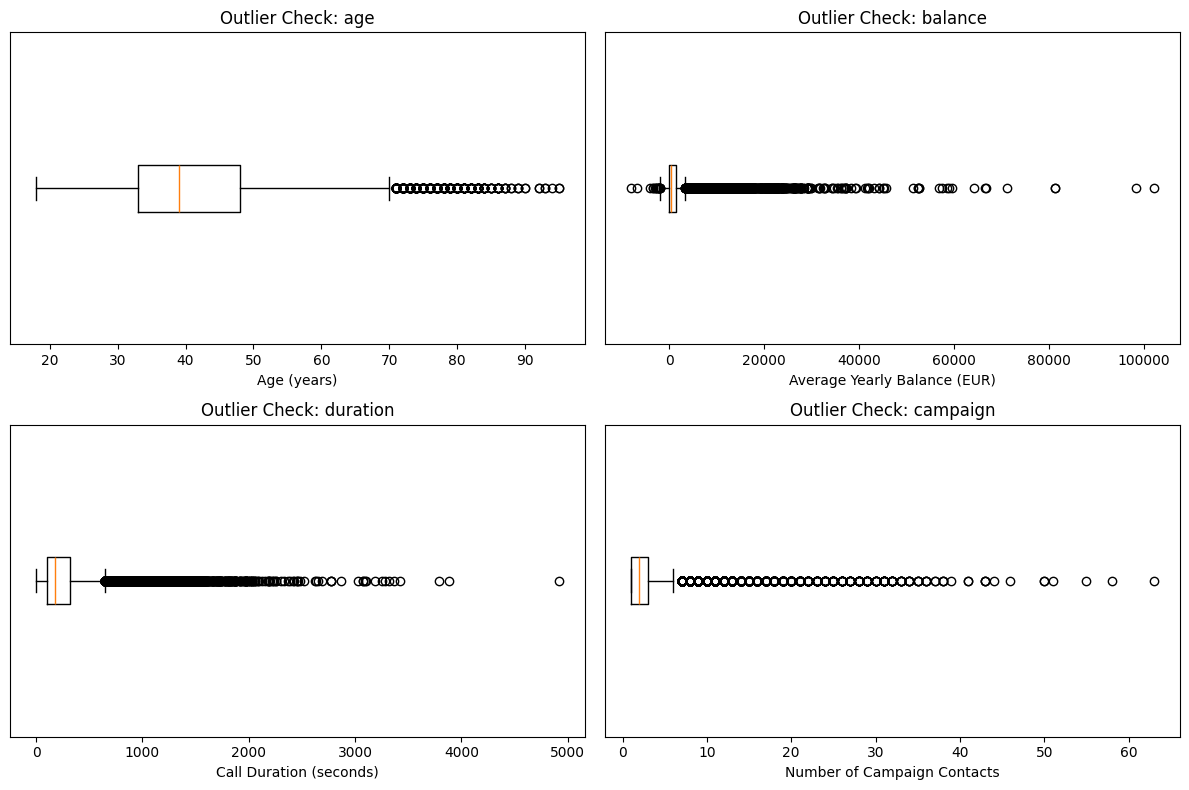

In [8]:
import matplotlib.pyplot as plt

labels = {
    "age": "Age (years)",
    "balance": "Average Yearly Balance (EUR)",
    "duration": "Call Duration (seconds)",
    "campaign": "Number of Campaign Contacts"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, outlier_columns):
    ax.boxplot(df_clean[col], vert=False)
    ax.set_title(f"Outlier Check: {col}")
    ax.set_xlabel(labels[col])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

### 6. Diagnostic Charts

**Outlier boxplots:** The boxplots show the distributions and statistical extremes of age, balance, duration and campaign. Balance, duration and campaign have long upper tails. The plotted outliers highlight records for review rather than confirmed errors.

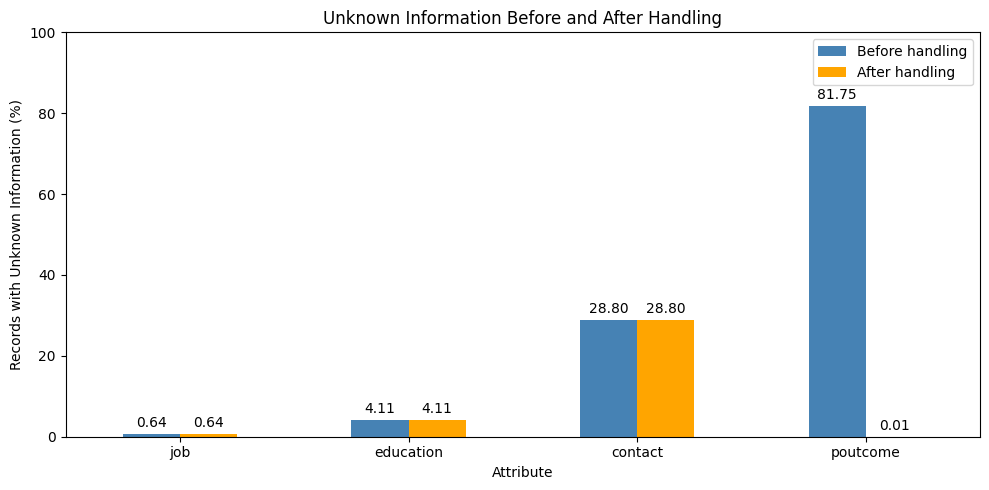

In [9]:
unknown_columns = ["job", "education", "contact", "poutcome"]

unknown_comparison = pd.DataFrame({
    "Before handling": (
        df[unknown_columns].eq("unknown").mean() * 100
    ),
    "After handling": (
        df_clean[unknown_columns].eq("unknown").mean() * 100
    )
})

ax = unknown_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "orange"]
)

ax.set_title("Unknown Information Before and After Handling")
ax.set_xlabel("Attribute")
ax.set_ylabel("Records with Unknown Information (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

**Unknown-information comparison:** The chart shows the percentage of unknown values before and after processing. The unknown percentage for poutcome decreases from 81.75% to approximately 0.01% because outcomes for customers without previous contact were reclassified as not_applicable. Unknown percentages for job, education and contact remain unchanged because these categories were retained and flagged.

,Count,Percentage (%)
y,,
no,39922,88.3
yes,5289,11.7


,Count,Percentage (%)
job,,
blue-collar,9732,21.53
management,9458,20.92
technician,7597,16.80
admin.,5171,11.44
services,4154,9.19
retired,2264,5.01
self-employed,1579,3.49
entrepreneur,1487,3.29
unemployed,1303,2.88


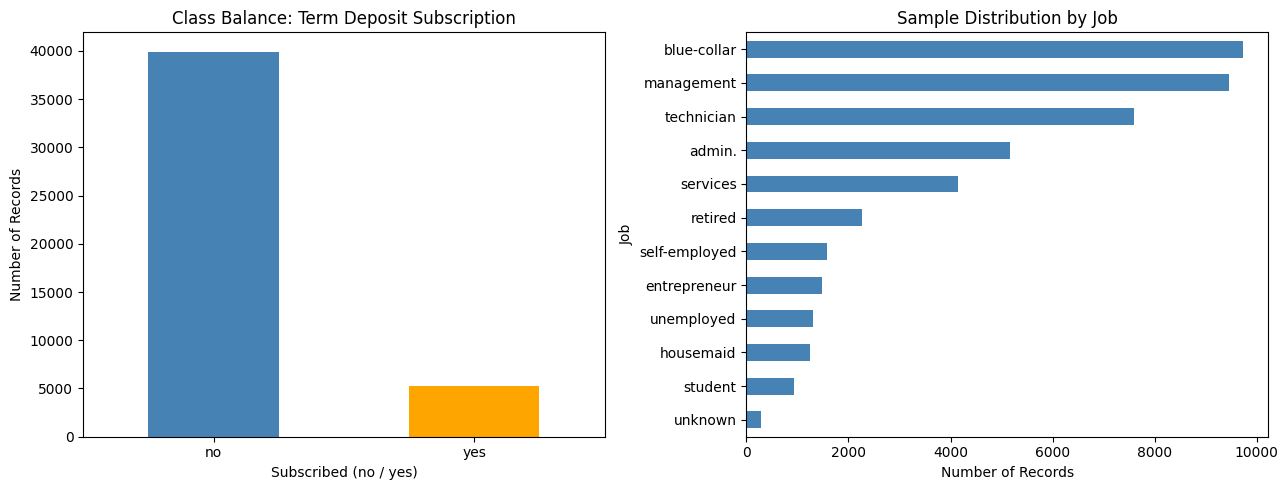

In [10]:
class_summary = (
    df_clean["y"]
    .value_counts()
    .reindex(["no", "yes"], fill_value=0)
    .to_frame("Count")
)

class_summary["Percentage (%)"] = (
    class_summary["Count"] / len(df_clean) * 100
).round(2)

display(class_summary)

job_summary = df_clean["job"].value_counts().to_frame("Count")

job_summary["Percentage (%)"] = (
    job_summary["Count"] / len(df_clean) * 100
).round(2)

display(job_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

class_summary["Count"].plot(
    kind="bar",
    ax=axes[0],
    color=["steelblue", "orange"]
)

axes[0].set_title("Class Balance: Term Deposit Subscription")
axes[0].set_xlabel("Subscribed (no / yes)")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=0)

job_summary["Count"].sort_values().plot(
    kind="barh",
    ax=axes[1],
    color="steelblue"
)

axes[1].set_title("Sample Distribution by Job")
axes[1].set_xlabel("Number of Records")
axes[1].set_ylabel("Job")

plt.tight_layout()
plt.show()

**Class and occupational distributions:** The subscription chart shows a class imbalance: 88.30% of records are labelled no and 11.70% are labelled yes. The occupational chart shows unequal sample sizes across job categories. These charts highlight limitations to consider in later analysis, but unequal group sizes alone do not establish unfairness.

### PII and Bias Risks

**Privacy:** The dataset does not contain direct identifiers such as names, identity numbers, telephone numbers or full addresses. However, balance and loan information are sensitive, while combinations of age, occupation and marital status may create re-identification risks if linked to external data. Access should be restricted, unnecessary data linking should be avoided, and shared reports should use aggregated results.

**Class imbalance:** There are 39,922 non-subscribers (88.30%) and 5,289 subscribers (11.70%). This imbalance could cause a future prediction model to favour the majority class. We retain the original distribution for profiling. If modelling is performed later, stratified splitting and suitable metrics such as precision, recall and F1-score should be used.

**Sampling bias:** The data covers customers contacted during one bank's marketing campaigns, so it may not represent all bank customers or the wider population. Occupational groups have different sample sizes; for example, blue-collar workers account for 21.53%, while students account for 2.07%. These differences indicate a need to assess representation rather than prove unfairness. Future analysis should report group sample sizes and compare coverage with an appropriate reference population.

### Conclusion

The dataset contains 45,211 records and 17 original columns. No null values, exact duplicate rows or violations of the tested validity and text-format rules were found. However, several fields contain unknown information.

Unknown values in job, education and contact were retained and flagged to avoid guessing or losing records. For previous campaign outcomes, 36,954 unknown values were reclassified as not_applicable because those customers had not previously been contacted. The remaining five unknown outcomes were retained and flagged.

IQR outliers in age, balance, duration and campaign were retained and flagged because statistical extremes alone do not prove data errors.

The processed data is suitable for demonstrating a banking data-quality workflow and for descriptive analysis of the recorded campaigns. Remaining limitations include unknown information, unverified extreme values, class imbalance and limited population coverage. The dataset alone does not demonstrate integration across multiple financial data sources.